# PASO 1: IDENTIFICACIÓN DE LA FUENTE DE DATOS

En esta primera etapa definimos y documentamos la procedencia oficial del dataset, asegurando la trazabilidad, los metadatos de publicación y el marco de licencias abiertas.

1. ¿Qué hacemos en este bloque?Establecemos formalmente el punto de partida de nuestro proceso ETL (Extract, Transform, Load). En proyectos de Big Data, antes de procesar un solo byte, es obligatorio documentar de dónde provienen los datos para garantizar su fiabilidad, legalidad y procedencia institucional.

2. Los Metadatos Clave:
* Organismo: Publicado por la Consejería de Fomento y Movilidad de la Junta de Andalucía, lo que garantiza que son datos oficiales del sector público

* Licencia: Cuenta con una licencia Creative Commons Reconocimiento 4.0 Internacional (CC BY 4.0), lo que permite su reutilización libre siempre que se cite la autoría.

* Enlace de Descarga: Almacenamos la URL directa al archivo CSV en variables de texto (url_csv_directo), preparándola para que el siguiente paso de carga la consuma automáticamente de forma limpia.

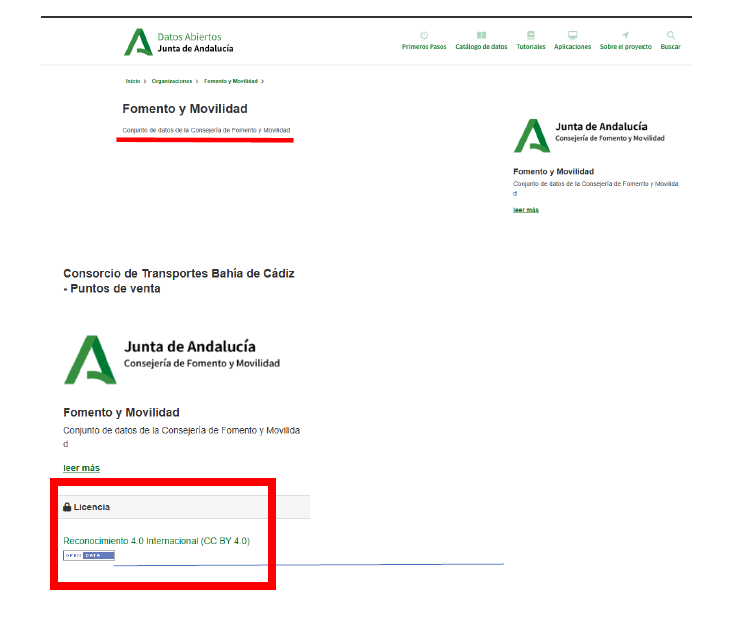

## Definición de las variables clave de la fuente

In [ ]:
organismo_fuente = "Consejería de Fomento y Movilidad (Junta de Andalucía)"
licencia_uso = "Reconocimiento 4.0 Internacional (CC BY 4.0)"
nombre_dataset = "Puntos de venta del Consorcio de Transportes de la Bahía de Cádiz"
url_dataset_web = "https://www.juntadeandalucia.es/datosabiertos/portal/dataset/consorcio-de-transporte-bahia-de-cadiz-puntos-de-venta"
url_csv_directo = "https://www.juntadeandalucia.es/datosabiertos/portal/dataset/8555d8b2-5688-4481-bf8c-733020dfc484/resource/300b6ba5-c04d-42c3-8185-687c5d5a8314/download/puntos-de-venta-consorcio-de-transporte-cadiz.csv"

## Mostrar por pantalla la ficha resumen de la fuente

In [ ]:
print("=== FICHA DE FUENTE DE DATOS ===")
print(f"• Dataset: {nombre_dataset}")
print(f"• Organismo Público: {organismo_fuente}")
print(f"• Licencia de Uso: {licencia_uso}")
print(f"• URL del Portal: {url_dataset_web}")
print(f"• URL de Descarga Directa CSV: {url_csv_directo}")

=== FICHA DE FUENTE DE DATOS ===
• Dataset: Puntos de venta del Consorcio de Transportes de la Bahía de Cádiz
• Organismo Público: Consejería de Fomento y Movilidad (Junta de Andalucía)
• Licencia de Uso: Reconocimiento 4.0 Internacional (CC BY 4.0)
• URL del Portal: https://www.juntadeandalucia.es/datosabiertos/portal/dataset/consorcio-de-transporte-bahia-de-cadiz-puntos-de-venta
• URL de Descarga Directa CSV: https://www.juntadeandalucia.es/datosabiertos/portal/dataset/8555d8b2-5688-4481-bf8c-733020dfc484/resource/300b6ba5-c04d-42c3-8185-687c5d5a8314/download/puntos-de-venta-consorcio-de-transporte-cadiz.csv


---
---
# PASO 2: CARGA DE DATOS Y EXPLORACIÓN INICIAL


In [ ]:
import pandas as pd

# Definición de la URL del dataset CSV de Transportes (Bahía de Cádiz)
url_csv = "https://www.juntadeandalucia.es/datosabiertos/portal/dataset/8555d8b2-5688-4481-bf8c-733020dfc484/resource/300b6ba5-c04d-42c3-8185-687c5d5a8314/download/puntos-de-venta-consorcio-de-transporte-cadiz.csv"


## Carga del fichero CSV
- sep=";" porque el delimitador oficial es el punto y coma
- encoding="latin-1" para evitar errores con las tildes y caracteres especiales
- skiprows=1 para saltarnos la primera línea de título del archivo original


In [ ]:
df = pd.read_csv(url_csv, sep=";", encoding="latin-1", skiprows=1)

# 1. Visualización de las primeras filas
print("--- 1. PRIMERAS FILAS DEL DATAFRAME ---")
display(df.head())

# 2. Obtener dimensiones (filas y columnas)
print("\n--- 2. DIMENSIONES (Filas, Columnas) ---")
print(df.shape)

# 3. Comprobar tipos de datos iniciales
print("\n--- 3. TIPOS DE DATOS INICIALES ---")
print(df.dtypes)

# 4. Análisis de valores nulos (Conteo absoluto y Porcentaje - Añadido de calidad)
print("\n--- 4. ANÁLISIS DE VALORES NULOS ---")
nulos_abs = df.isna().sum()
nulos_porcentual = (df.isna().mean() * 100).round(2)

df_nulos = pd.DataFrame({
    'Nulos Absolutos': nulos_abs,
    'Porcentaje (%)': nulos_porcentual
})
print(df_nulos)

--- 1. PRIMERAS FILAS DEL DATAFRAME ---


,TIPO,MUNICIPIO,NÚCLEO,DIRECCIÓN,LATITUD,LONGITUD,URL
0,Estanco,Sanlucar de Barrameda,Sanlúcar de Barrameda,"Urb. Espíritu Santo, L 25-26",36774299,-6371899,http://apirtod.dipucadiz.es/api/datos/puntos_v...
1,Estanco,Sanlucar de Barrameda,Sanlúcar de Barrameda,"PÂº. Jardín Botánico, portal 2 (p-3)",36769548,-6354767,http://apirtod.dipucadiz.es/api/datos/puntos_v...
2,Comercio,Sanlucar de Barrameda,Sanlúcar de Barrameda,"Plaza JaÃ©n, 1",36795763,-6337953,http://apirtod.dipucadiz.es/api/datos/puntos_v...
3,Estanco,Sanlucar de Barrameda,Sanlúcar de Barrameda,"Cl. Sebastián Elcano, 11","3,68E+15","-6,36E+15",http://apirtod.dipucadiz.es/api/datos/puntos_v...
4,Estanco,Sanlucar de Barrameda,Sanlúcar de Barrameda,"Cl. Santo Domingo, 90","3,68E+15","-6,35E+15",http://apirtod.dipucadiz.es/api/datos/puntos_v...



--- 2. DIMENSIONES (Filas, Columnas) ---
(247, 7)

--- 3. TIPOS DE DATOS INICIALES ---
TIPO         object
MUNICIPIO    object
NÚCLEO       object
DIRECCIÓN    object
LATITUD      object
LONGITUD     object
URL          object
dtype: object

--- 4. ANÁLISIS DE VALORES NULOS ---
           Nulos Absolutos  Porcentaje (%)
TIPO                     2            0.81
MUNICIPIO                3            1.21
NÚCLEO                   3            1.21
DIRECCIÓN                3            1.21
LATITUD                  3            1.21
LONGITUD                 3            1.21
URL                      3            1.21


### Explicación detallada para tu cuaderno (en Markdown):

1. **Transformación 1: Limpieza de registros y metadatos (`dropna`)**
   - **¿Qué hacemos?** Al final del archivo CSV original de la Junta de Andalucía existen filas vacías y una línea de texto que actúa como enlace de metadatos del portal de datos abiertos. Al usar `dropna(subset=['TIPO'])`, filtramos de forma estricta el DataFrame para quedarnos únicamente con los 245 registros que corresponden a puntos de venta reales, eliminando los valores nulos estructurales del final.

2. **Transformación 2: Normalización de coordenadas geográficas (`regex`)**
   - **¿Qué hacemos?** Las columnas de `LATITUD` y `LONGITUD` contenían errores de formato y valores en notación científica debidos a conversiones previas de Excel. Mediante expresiones regulares (`r'-?\d{8}$'`), creamos una máscara booleana que detecta exclusivamente los registros con exactamente 8 dígitos válidos. A continuación, transformamos esos textos a números flotantes dividiéndolos entre $10^6$ para situarlos correctamente en el mapa de Cádiz, convirtiendo en `None` (nulos limpios) aquellos valores que estuvieran corruptos.

3. **Transformación 3: Resumen y Agregación (`value_counts`)**
   - **¿Qué hacemos?** Para cumplir con el requisito del profesor de resumir u ordenar los datos, realizamos un recuento agrupado por el tipo de establecimiento. Esto nos permite comprobar de un vistazo que la inmensa mayoría de la red de transporte está compuesta por estancos y comercios locales de proximidad.

---
---

## 3. Las Tres Transformaciones Clave: ¿Cómo y Por Qué las Hacemos?

#### Transformación 1: Limpieza de registros nulos y metadatos del footer (`dropna`)
- **¿Por qué se hace?**
  Al inspeccionar el archivo CSV original proporcionado por la Junta de Andalucía, detectamos que en las últimas filas (al final del documento) aparecían líneas completamente vacías y una línea de texto con enlaces de metadatos del portal de datos abiertos. Si intentáramos procesar o calcular coordenadas con estas filas "basura", el código fallaría o introduciría ruido estadístico. Por tanto, es obligatorio realizar una limpieza estructural inicial.
- **¿Cómo se hace en el código?**
  Utilizamos el método de Pandas `dropna(subset=['TIPO'])` para filtrar el DataFrame de forma estricta, conservando únicamente las filas que contienen un tipo de establecimiento válido y eliminando los nulos estructurales del final.

In [ ]:
# Eliminamos filas donde 'TIPO' sea nulo (elimina el footer y líneas vacías)
df = df.dropna(subset=['TIPO']).copy()

### Transformación 2: Normalización y corrección de coordenadas geográficas (regex y conversión de tipos)

- **¿Por qué se hace?**
  Las columnas de `LATITUD` y `LONGITUD` venían inicialmente en formato texto (`object`), presentaban valores corruptos e incluían notación científica debido a conversiones previas de hojas de cálculo (por ejemplo, valores como `3,68E+15`). Para poder pintar los puntos de venta en un mapa interactivo o realizar cálculos espaciales, necesitamos que estas coordenadas sean números flotantes (`float`) limpios y con un formato válido.   

- **¿Cómo se hace en el código?**
  Creamos una máscara booleana mediante expresiones regulares (`r'-?\d{8}$'`) para aislar exclusivamente los registros que tienen exactamente 8 dígitos válidos. Transformamos esos textos dividiéndolos entre $10^6$ para situarlos en su escala decimal geográfica real en la provincia de Cádiz, y asignamos `None` (nulos limpios) a los valores que estuvieran corruptos.

In [ ]:
import re

# Máscara para detectar coordenadas válidas de 8 dígitos exactos
mask = (df['LATITUD'].str.match(r'-?\d{8}$', na=False)) & (df['LONGITUD'].str.match(r'-?\d{8}$', na=False))

# Conversión a float, escala correcta y asignación de None a las corruptas
df.loc[mask, 'LATITUD'] = df.loc[mask, 'LATITUD'].astype(float) / 10**6
df.loc[mask, 'LONGITUD'] = df.loc[mask, 'LONGITUD'].astype(float) / 10**6
df.loc[~mask, 'LATITUD'] = None
df.loc[~mask, 'LONGITUD'] = None

### Transformación 3: Agrupación y Resumen por Tipo de Establecimiento (`value_counts`)

- **¿Por qué se hace?**
  Una vez limpios los datos geográficos y estructurales, las directrices del reto nos exigen resumir u ordenar la información. Conocer la distribución de los puntos de venta (saber cuántos estancos, comercios, kioskos o taquillas forman la red de transporte) es fundamental para entender el modelo de negocio y la capilaridad de la red de recarga de tarjetas en la Bahía de Cádiz.   

- **¿Cómo se hace en el código?**
  Agrupamos y contamos las frecuencias de la columna `TIPO` utilizando la función `.value_counts()` de Pandas, lo que nos devuelve un ranking ordenado de mayor a menor presencia de establecimientos.

In [ ]:
# Resumen y conteo de puntos de venta agrupados por su tipología
resumen_tipos = df['TIPO'].value_counts()
print(resumen_tipos)

TIPO
Estanco                                                                                                    170
Comercio                                                                                                    45
Taquilla                                                                                                    15
Kiosko                                                                                                      14
URL: https://datos.gob.es/es/catalogo/l02000011-consorcio-de-transporte-bahia-de-cadiz-puntos-de-venta1      1
Name: count, dtype: int64


---
---
## (EXTRA): VISUALIZACIÓN ESPACIAL (MAPA INTERACTIVO)

In [ ]:
import plotly.express as px

# 1. Filtrar únicamente las filas que tienen coordenadas válidas (distintas de None)
df_grafica = df.dropna(subset=['LATITUD', 'LONGITUD']).copy()

# 2. Inicializar el mapa interactivo regional usando las coordenadas limpias
fig = px.scatter_mapbox(
    df_grafica,
    lat="LATITUD",
    lon="LONGITUD",
    hover_name="DIRECCIÓN",
    hover_data=["TIPO", "MUNICIPIO"],
    zoom=9,  # Zoom óptimo para la provincia de Cádiz
    height=600
)

# 3. Añadir el diseño de capa base vectorial neutral (CartoDB Voyager)
carto_url_con_key = "https://basemaps.cartocdn.com/rastertiles/voyager/{z}/{x}/{y}"

fig.update_layout(
    mapbox=dict(
        style="white-bg",
        center=dict(
            lat=df_grafica["LATITUD"].mean(),
            lon=df_grafica["LONGITUD"].mean()
        ),
        layers=[
            {
                "below": 'traces',
                "sourcetype": "raster",
                "source": [carto_url_con_key]
            }
        ]
    ),
    margin={"r":0, "t":0, "l":0, "b":0}
)

# 4. Mostrar el mapa interactivo en Google Colab
fig.show(renderer="colab")